## Title :
Exercise: Simple Lasso and Ridge Regularization

## Description :
The aim of this exercise is to understand **Lasso and Ridge regularization.**

For this we will plot the predictor vs coefficient as a horizontal bar chart. The graph will look similar to the one given below.

<img src="../fig/fig2.png" style="width: 500px;">

## Data Description:

## Instructions:

- Read the dataset and assign the predictor and response variables.
- Split the dataset into train and validation sets.
- Fit a multi-linear regression model.
- Compute the validation MSE of the model.
- Compute the coefficient of the predictors and store to the plot later.
- Implement Lasso regularization by specifying an alpha value. Repeat steps 4 and 5.
- Implement Ridge regularization by specifying the same alpha value. Repeat steps 4 and 5.
- Plot the coefficient of all the 3 models in one graph as shown above.

## Hints: 

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.normalize.html" target="_blank">sklearn.normalize()</a>
Scales input vectors individually to the unit norm (vector length)

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html" target="_blank">sklearn.train_test_split()</a>
Splits the data into random train and test subsets

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html" target="_blank">sklearn.LinearRegression()</a>
LinearRegression fits a linear model

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression.fit" target="_blank">sklearn.fit()</a>
Fits the linear model to the training data

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression.predict" target="_blank">sklearn.predict()</a>
Predict using the linear modReturns the coefficient of the predictors in the model.

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html" target="_blank">mean_squared_error()</a>
Mean squared error regression loss

<a href="http://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html" target="_blank">sklearn.Lasso()</a>
Linear Model trained with L1 prior as a regularizer

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html" target="_blank">sklearn.Ridge()</a>
Linear least squares with L2 regularization

**Note:** This exercise is auto-graded and you can try multiple attempts. 

In [169]:
# Import necessary libraries
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import preprocessing
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures


### Reading the dataset

In [170]:
# Read the file "Boston_housing.csv" as a Pandas dataframe
df = pd.read_csv("Boston_housing.csv")


## Predictors & Response variables

Select the following columns as predictors
- crim
- indus
- nox
- rm
- age
- dis
- rad
- tax
- ptratio
- black
- lstat

#### Select the 'medv' column as response variable

In [ ]:
# Select a subdataframe of predictors mentioned above
X = df[["crim", "indus", "nox", "rm", "age", "dis", "rad", "tax", "ptratio", "black", "lstat"]]

# Normalize the values of the dataframe 
X_norm = preprocessing.normalize(X)

# Select medv as the response variable
y = df["medv"]


### Split the dataset into train and validation sets


In [172]:
### edTest(test_random) ###
# Split the data into train and validation sets with 70% train data and
# random_state as 31
X_train, X_val, y_train, y_val = train_test_split(X_norm, y, train_size = 0.7, random_state=31)


### Multi-linear Regression Analysis

In [173]:
# Initialize a Linear Regression model
lreg = LinearRegression()

# Fit the linear model on the train data
lreg.fit(X_train, y_train)

# Predict on the validation data
y_val_pred = lreg.predict(X_val)


In [174]:
# Use the mean_squared_error function to compute the validation mse
mse = mean_squared_error(y_val, y_val_pred)

# Print the MSE value
print ("Multi-linear regression validation MSE is", mse)


Multi-linear regression validation MSE is 21.581146124032493


### Obtaining the coefficients of the predictors

In [175]:
# Helper code to create a dictionary of the coefficients 
# along with the predictors as keys
lreg_coef = dict(zip(X.columns, np.transpose(lreg.coef_)))

# Linear regression coefficients for plotting
lreg_x = list(lreg_coef.keys())
lreg_y = list(lreg_coef.values())


### Implementing Lasso regularization

In [176]:
# Create a Lasso Regression model with alpha as 0.008
lasso_reg = Lasso(alpha=0.008)

# Fit the model on the train data
lasso_reg.fit(X_train, y_train)

# Predict on the validation data using the trained model
y_val_pred = lasso_reg.predict(X_val)


### Computing the MSE with Lasso regularization

In [177]:
# Calculate the validation MSE
mse_lasso = mean_squared_error(y_val, y_val_pred)

# Print the validation MSE
print ("Lasso validation MSE is", mse_lasso)


Lasso validation MSE is 21.70503127596723


In [178]:
# Hhelper code to make a dictionary of the predictors 
# along with the coefficients associated with them
lasso_coef = dict(zip(X.columns, np.transpose(lasso_reg.coef_))) 

# Get the Lasso regularisation coefficients for plotting
lasso_x = list(lasso_coef.keys())
lasso_y = list(lasso_coef.values())


### Implementing Ridge regularization

In [179]:
# Create a Ridge Regression model with alpha as 0.008
ridgeReg = Ridge(alpha=0.008)

# Fit the model on the train data
ridgeReg.fit(X_train, y_train)

# Predict the trained model on the validation data
y_val_pred = ridgeReg.predict(X_val)


### Computing the MSE with Ridge regularization

In [180]:
### edTest(test_mse) ###

# Calculate the validation MSE
mse_ridge = mean_squared_error(y_val, y_val_pred)

# Print he valdiation MSE
print ("Ridge validation MSE is", mse_ridge)


Ridge validation MSE is 21.586820373447566


### Obtaining the coefficients of the predictors

In [181]:
# Helper code to make a dictionary of the predictors 
# along with the coefficients associated with them 
ridge_coef = dict(zip(X.columns, np.transpose(ridgeReg.coef_))) 

# Ridge regularisation coefficients for plotting
ridge_x = list(ridge_coef.keys())
ridge_y = list(ridge_coef.values())


### Plotting the graph

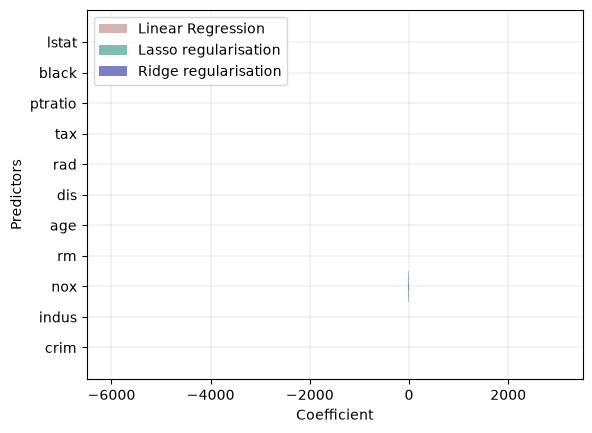

In [182]:
# Helper code below to visualise your results

plt.rcdefaults()

plt.barh(lreg_x,lreg_y,1.0, align='center',color="#D3B4B4", label="Linear Regression")
plt.barh(lasso_x,lasso_y,0.75 ,align='center',color="#81BDB2",label = "Lasso regularisation")
plt.barh(ridge_x,ridge_y,0.25 ,align='center',color="#7E7EC0", label="Ridge regularisation")
plt.grid(linewidth=0.2)
plt.xlabel("Coefficient")
plt.ylabel("Predictors")
plt.legend(loc='best')
plt.xlim(-6500,3500)
plt.show()


#### ⏸ How does the performance of Lasso and Ridge regression compare with that of Linear regression?

In [183]:
### edTest(test_chow1) ###
# Submit an answer choice as a string below 
answer1 = '___'


#### ⏸ Change the alpha values for both, Lasso and Ridge, to 1000. What happens to the coefficients?


In [184]:
### edTest(test_chow2) ###
# Submit an answer choice as a string below 
answer2 = 'The coeficients became extremely small for ridge, and zero for lasso'
